In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, pickle
d = "/content/drive/MyDrive/radar-trafico/data/raw/session2_center"

# 1. ¿El vídeo está completo?
print(os.path.getsize(f"{d}/video.avi") == 9508744968)

# 2. ¿El pkl se abre?
with open(f"{d}/gt_data.pkl", "rb") as f:
    gt = pickle.load(f, encoding="latin1")
print(type(gt), gt.keys() if isinstance(gt, dict) else len(gt))

True
<class 'dict'> dict_keys(['distanceMeasurement', 'measurementLines', 'cars', 'fps', 'invalidLanes', 'laneDivLines'])


In [ ]:
!mkdir -p /content/drive/MyDrive/radar-trafico/data/raw
!cp -r /content/brno/2016-ITS-BrnoCompSpeed/dataset/session2_center /content/drive/MyDrive/radar-trafico/data/raw/

cp: cannot stat '/content/brno/2016-ITS-BrnoCompSpeed/dataset/session2_center': No such file or directory


In [ ]:
print(gt["fps"])
car = gt["cars"][39]
print(car.keys())
print(car)

50.0
dict_keys(['acceleration', 'intersections', 'carId', 'timeIntersectionLastShifted', 'valid', 'laneIndex', 'speed'])
{'acceleration': -0.523, 'intersections': [{'measurementLineId': 4, 'videoTime': 466.216972}, {'measurementLineId': 0, 'videoTime': 467.410116}], 'carId': 40, 'timeIntersectionLastShifted': 467.410116, 'valid': True, 'laneIndex': {1}, 'speed': 84.4812}


(1080, 1920, 3) (1080, 1920) [  0 255]


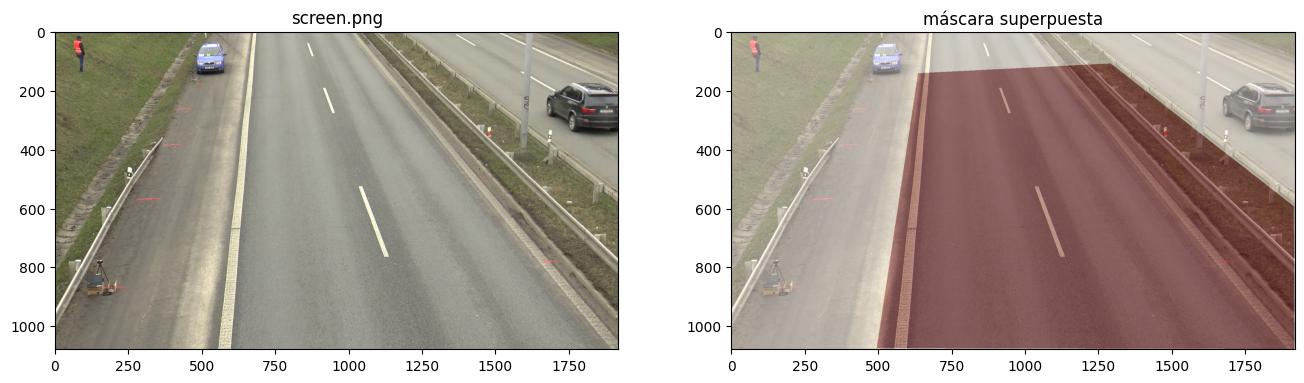

In [ ]:
import numpy as np
import cv2, matplotlib.pyplot as plt

screen = cv2.cvtColor(cv2.imread(f"{d}/screen.png"), cv2.COLOR_BGR2RGB)
mask = cv2.imread(f"{d}/video_mask.png", cv2.IMREAD_GRAYSCALE)
print(screen.shape, mask.shape, np.unique(mask))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(screen); ax[0].set_title("screen.png")
ax[1].imshow(screen); ax[1].imshow(mask, alpha=0.4, cmap="Reds"); ax[1].set_title("máscara superpuesta")
plt.show()

In [ ]:
car = gt["cars"][600]
print(car.keys())
print(car["acceleration"])
print(car["intersections"])
print(car["carId"])
print(car["timeIntersectionLastShifted"])
print(car["valid"])
print(car["laneIndex"])
print(car["speed"])

dict_keys(['acceleration', 'intersections', 'carId', 'timeIntersectionLastShifted', 'valid', 'laneIndex', 'speed'])
-0.243
[{'measurementLineId': 4, 'videoTime': 1681.359062}, {'measurementLineId': 0, 'videoTime': 1682.705316}]
601
1682.705316
True
{0}
74.8728


In [ ]:
intersections = car["intersections"]
print(intersections)

def tiempoCoche(intersections):         # tiempo que tarda en cruzar las lineas 0 y 4 del dataset

    tiempos = []
    for intersection in intersections:
        tiempos.append(intersection["videoTime"])

    linea0 = tiempos[1]
    linea4 = tiempos[0]

    return linea4, linea0

print(tiempoCoche(intersections))

[{'measurementLineId': 4, 'videoTime': 1681.359062}, {'measurementLineId': 0, 'videoTime': 1682.705316}]
(1681.359062, 1682.705316)


In [ ]:
from posix import write
FRAMES_POR_SEGUNDO = 100

def leer_frames(rutaVideo, tInicio, tFinal):
    cap = cv2.VideoCapture(rutaVideo)

    frameInicio = round(tInicio * FRAMES_POR_SEGUNDO)
    frameFinal = round(tFinal * FRAMES_POR_SEGUNDO)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frameInicio)

    for i in range(frameInicio, frameFinal):
        ok, frame = cap.read()

        if not ok:
          break

        yield i, i / FRAMES_POR_SEGUNDO, frame

    cap.release()

def mostrar_clip(rutaVideo, tInicio, tFinal, modelo, salida="clip.mp4"):
  writer = None

  for i, t, frame in leer_frames(rutaVideo, tInicio, tFinal):

    resultado = modelo(frame, classes=[2, 3, 5, 7], verbose=False)[0]  # importante, filtro para vehiculos
    frame = resultado.plot()

    if writer is None:
      h, w = frame.shape[:2]
      writer = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), 100, (w, h))
    writer.write(frame)
  writer.release()

car = gt["cars"][600]
intersections = car["intersections"]
tInicio, tFinal = tiempoCoche(intersections)

In [ ]:
!pip install ultralytics

from IPython.display import Video
from ultralytics import YOLO
!rm -f clip.mp4 clip_h264.mp4

modelo = YOLO("yolo11n.pt")

mostrar_clip("/content/drive/MyDrive/radar-trafico/data/raw/session2_center/video.avi", tInicio, tFinal, modelo)

!ffprobe -v error -count_frames -select_streams v:0 -show_entries stream=nb_read_frames -of csv=p=0 clip.mp4
!ffmpeg -y -loglevel error -i clip.mp4 -c:v libx264 clip_h264.mp4
Video("clip_h264.mp4", embed=True)

135


In [ ]:
from IPython.display import Video, display

modelo = YOLO("yolo11n.pt")

import random
random.seed(42)

candidatos = [
    c for c in gt["cars"]
    if c["valid"]
    and len(c["intersections"]) == 2
    and max(i["videoTime"] for i in c["intersections"]) < 1200   # solo el bloque de ajuste
]

muestra = random.sample(candidatos, 10)

NO_MOSTRAR_VIDEOS = False  # no imprime los video y me deja guardar el notebook

if NO_MOSTRAR_VIDEOS:
  for car in muestra:
      intersections = car["intersections"]
      if len(intersections) == 2:
          cid = car["carId"]
          tInicio, tFinal = tiempoCoche(intersections)
          mostrar_clip("/content/drive/MyDrive/radar-trafico/data/raw/session2_center/video.avi", tInicio, tFinal, modelo, salida=f"clip_{cid}.mp4")
          !ffmpeg -y -loglevel error -i clip_{cid}.mp4 -c:v libx264 clip_{cid}_h264.mp4
          display(Video(f"clip_{cid}_h264.mp4", embed=True))

325 candidatos


In [ ]:
display(Video(f"clip_65_h264.mp4", embed=True))

In [ ]:
CLIPS_TRACKING = {
    "simple" : {
        "carId" : 72,
        "margen" : 0.5,
        "nota" : "turismo solo, carril izquierdo, sin mas coches"
    },

    "paralelo" : {
        "carId" : 350,
        "margen" : 0.5,
        "nota" : "varios coches en escena, en ambos carriles"
    },

    "adelantamiento" : {
        "carId" : 65,
        "margen" : 0.5,
        "nota" : "varios coches en ambos carriles, coche adelantando camion por izquierda"
    }
}

In [ ]:
def coche_por_id(gt, carId):
    for c in gt["cars"]:
        if c["carId"] == carId:
            return c
    raise ValueError(f"No existe el carId {carId}")

In [ ]:
car = coche_por_id(gt, CLIPS_TRACKING["paralelo"]["carId"])
tInicio, tFinal = tiempoCoche(car["intersections"])

ruta = "/content/drive/MyDrive/radar-trafico/data/raw/session2_center/video.avi"

gen = leer_frames(ruta, tInicio, tFinal)

_, tA, frameA = next(gen)
_, tB, frameB = next(gen)

resA = modelo(frameA, classes=[2, 3, 5, 7], verbose=False)[0]
resB = modelo(frameB, classes=[2, 3, 5, 7], verbose=False)[0]

print(resA.boxes)


ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2., 2., 2., 2., 7., 2.], device='cuda:0')
conf: tensor([0.7757, 0.7610, 0.6959, 0.6539, 0.4268, 0.2792], device='cuda:0')
data: tensor([[4.7846e+02, 3.8983e+01, 5.8136e+02, 1.4699e+02, 7.7574e-01, 2.0000e+00],
        [1.7812e+03, 3.1210e+02, 1.9193e+03, 5.0635e+02, 7.6098e-01, 2.0000e+00],
        [8.9964e+02, 2.3962e+01, 1.0184e+03, 1.4180e+02, 6.9589e-01, 2.0000e+00],
        [8.1218e+02, 1.8798e+02, 9.7872e+02, 3.7567e+02, 6.5391e-01, 2.0000e+00],
        [7.0893e+02, 9.4018e-01, 8.2404e+02, 7.6079e+01, 4.2678e-01, 7.0000e+00],
        [7.0836e+02, 0.0000e+00, 8.2317e+02, 7.5591e+01, 2.7920e-01, 2.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (1080, 1920)
shape: torch.Size([6, 6])
xywh: tensor([[ 529.9127,   92.9872,  102.8998,  108.0093],
        [1850.2329,  409.2269,  138.1417,  194.2478],
        [ 959.0369,   82.8794,  118.7955,  117.8340],
        [ 895.4531,  281.8263,  166.5398,  187.

In [ ]:
import pandas as pd

ruta = "/content/drive/MyDrive/radar-trafico/data/raw/session2_center/video.avi"

mask = cv2.imread(f"{d}/video_mask.png", cv2.IMREAD_GRAYSCALE)
car = coche_por_id(gt, CLIPS_TRACKING["paralelo"]["carId"])
tInicio, tFinal = tiempoCoche(car["intersections"])

def detectar_clip(ruta, tInicio, tFinal, modelo, mask, clases=(2, 3, 5, 7)):
    filas = []
    for idx, t, frame in leer_frames(ruta, tInicio, tFinal):
        res = modelo(frame, classes=list(clases), verbose=False)[0]
        cajas = res.boxes.xyxy.cpu().numpy()
        confianza = res.boxes.conf.cpu(). numpy()
        clase = res.boxes.cls.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), conf, cls in zip(cajas, confianza, clase):
            px = min(int((x1 + x2) / 2), mask.shape[1] - 1)
            py = min(int(y2), mask.shape[0] - 1)

            if mask[py, px] > 0:
                filas.append({
                    "frame": idx, "t": t,
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                    "conf": conf, "cls": cls,
                })

    return pd.DataFrame(filas)

df = detectar_clip(ruta, tInicio, tFinal, modelo, mask)
print(len(df), "cajas en", df["frame"].nunique(), "frames")
print(df.groupby("frame").size().value_counts())

298 cajas en 106 frames
3    54
2    36
4    16
Name: count, dtype: int64


In [47]:
COLORES = {2: (0, 255, 0), 3: (255, 0, 255), 5: (0, 165, 255), 7: (0, 0, 255)}  # BGR: coche verde, camión rojo

def dibujar_df(ruta, tInicio, tFinal, df, mask, salida="detecciones.mp4"):
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    writer = None
    for idx, t, frame in leer_frames(ruta, tInicio, tFinal):
        cv2.drawContours(frame, contornos, -1, (255, 255, 0), 2)

        for _, f in df[df["frame"] == idx].iterrows():
            x1, y1, x2, y2 = int(f.x1), int(f.y1), int(f.x2), int(f.y2)
            color = COLORES.get(int(f.cls), (255, 255, 255))
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.circle(frame, ((x1 + x2) // 2, y2), 6, color, -1)
            cv2.putText(frame, f"{int(f.cls)} {f.conf:.2f}", (x1, y1 - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        n = (df["frame"] == idx).sum()
        cv2.putText(frame, f"t={t:.2f}s  cajas={n}", (30, 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 255), 3)

        if writer is None:
            h, w = frame.shape[:2]
            writer = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), 25, (w, h))
            assert writer.isOpened()
        writer.write(frame)
    writer.release()

In [48]:
dibujar_df(ruta, tInicio, tFinal, df, mask)

In [50]:
!ffmpeg -y -loglevel error -i detecciones.mp4 -c:v libx264 detecciones_h264.mp4
display(Video("detecciones_h264.mp4", embed=True))